In [1]:
import pandas as pd, numpy as np, glob, joblib, time, os
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, confusion_matrix, f1_score

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception as e:
    HAVE_XGB = False
print("All imports OK | XGBoost available:", HAVE_XGB)

Matplotlib is building the font cache; this may take a moment.


All imports OK | XGBoost available: False


In [2]:
LABEL_MAP = {
    "BENIGN": "Benign",
    "FTP-Patator": "BruteForce", "SSH-Patator": "BruteForce",
    "DoS Hulk": "DoS", "DoS GoldenEye": "DoS",
    "DoS slowloris": "DoS", "DoS Slowhttptest": "DoS",
    "PortScan": "PortScan",
}

def load_day(path, benign_cap=75_000):
    df = pd.read_csv(path, encoding="latin1")
    df.columns = df.columns.str.strip()            # column names have leading spaces
    df["Label"] = df["Label"].str.strip().map(LABEL_MAP)
    df = df.dropna(subset=["Label"])               # drop labels outside our 4 classes
    feats = df.columns.drop("Label")
    df[feats] = df[feats].replace([np.inf, -np.inf], np.nan).astype("float32")
    df = df.dropna()                               # remove rows with NaN/Inf
    benign = df[df.Label == "Benign"]
    if len(benign) > benign_cap:                   # sample benign down to save RAM
        benign = benign.sample(benign_cap, random_state=42)
    return pd.concat([benign, df[df.Label != "Benign"]])

In [3]:
frames = []
for f in sorted(glob.glob("data/*.csv")):
    t0 = time.time()
    d = load_day(f)
    print(f"{os.path.basename(f):55s} -> {d.shape}  ({time.time()-t0:.0f}s)")
    frames.append(d)

df = pd.concat(frames, ignore_index=True)
before = len(df)
df = df.drop_duplicates()                           # BEFORE splitting, to avoid leakage
print(f"\nDropped {before - len(df):,} duplicate rows")
print(f"Final shape: {df.shape}")
print(df.Label.value_counts())

Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv    -> (233804, 79)  (4s)
Monday-WorkingHours.pcap_ISCX.csv                       -> (75000, 79)  (8s)
Tuesday-WorkingHours.pcap_ISCX.csv                      -> (88832, 79)  (7s)
Wednesday-workingHours.pcap_ISCX.csv                    -> (326712, 79)  (11s)

Dropped 141,926 duplicate rows
Final shape: (582422, 79)
Label
Benign        288848
DoS           193730
PortScan       90694
BruteForce      9150
Name: count, dtype: int64


In [4]:
print("Classes:", sorted(df.Label.unique()))
print("Any NaN left:", df.drop(columns="Label").isna().any().any())
print("Number of features:", df.shape[1] - 1)
print("Memory (MB):", round(df.memory_usage(deep=True).sum() / 1e6))

df.to_pickle("data/clean_2017.pkl")                 # fast reload if the kernel restarts

Classes: ['Benign', 'BruteForce', 'DoS', 'PortScan']
Any NaN left: False
Number of features: 78
Memory (MB): 223


In [5]:
X = df.drop(columns="Label")
y = df["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTrain class counts:\n", y_train.value_counts())
print("\nTest class counts:\n", y_test.value_counts())

Train: (465937, 78) | Test: (116485, 78)

Train class counts:
 Label
Benign        231078
DoS           154984
PortScan       72555
BruteForce      7320
Name: count, dtype: int64

Test class counts:
 Label
Benign        57770
DoS           38746
PortScan      18139
BruteForce     1830
Name: count, dtype: int64


In [6]:
t0 = time.time()
rf0 = RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=42)
rf0.fit(X_train, y_train)
print(f"Ranking forest trained in {time.time()-t0:.0f}s")

Ranking forest trained in 48s


Max Packet Length              0.0893
Packet Length Std              0.0825
Packet Length Variance         0.0714
Bwd Packet Length Max          0.0692
Avg Bwd Segment Size           0.0568
Packet Length Mean             0.0484
Average Packet Size            0.0462
Total Length of Bwd Packets    0.0418
Destination Port               0.0281
Fwd Packet Length Mean         0.0263
Bwd Packet Length Std          0.0239
Fwd Packet Length Max          0.0225
Flow IAT Max                   0.0225
Subflow Fwd Bytes              0.0224
Bwd Packet Length Mean         0.0214
Subflow Bwd Bytes              0.0199
Fwd IAT Mean                   0.0188
Avg Fwd Segment Size           0.0169
Bwd Packets/s                  0.0154
Flow Bytes/s                   0.0146
Init_Win_bytes_forward         0.0145
Flow IAT Std                   0.0139
Fwd IAT Total                  0.0135
ACK Flag Count                 0.0134
PSH Flag Count                 0.0120
dtype: float64

Destination Port in top 25: True


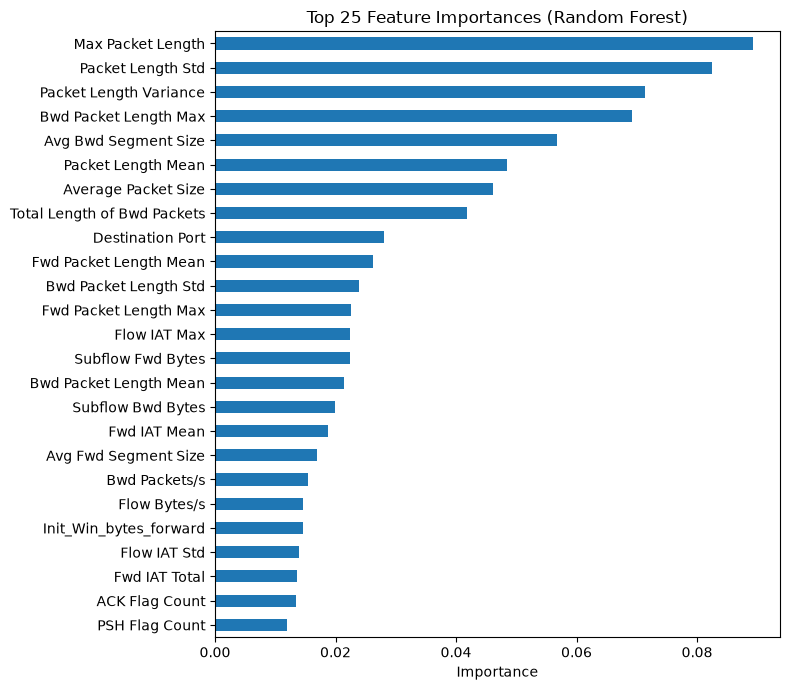

In [7]:
imp = pd.Series(rf0.feature_importances_, index=X.columns).sort_values(ascending=False)
top25 = imp.head(25).index.tolist()

print(imp.head(25).round(4))
print("\nDestination Port in top 25:", "Destination Port" in top25)

plt.figure(figsize=(8, 7))
imp.head(25)[::-1].plot(kind="barh")
plt.title("Top 25 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("figures/feature_importance.png", dpi=200)
plt.show()

imp.head(25).rename("importance").to_csv("figures/top25_features.csv")

In [8]:
X_train = X_train[top25]
X_test = X_test[top25]
print("Train:", X_train.shape, "| Test:", X_test.shape)

joblib.dump((X_train, X_test, y_train, y_test, top25), "data/split_2017.pkl")

Train: (465937, 25) | Test: (116485, 25)


['data/split_2017.pkl']

In [9]:
t0 = time.time()
rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",   # gives the rare BruteForce class more weight
    n_jobs=-1,
    random_state=42,
)
rf.fit(X_train, y_train)
rf_time = time.time() - t0
print(f"Random Forest trained in {rf_time:.0f}s")

Random Forest trained in 82s


In [10]:
t0 = time.time()
if HAVE_XGB:
    gb_name = "XGBoost"
    le = LabelEncoder().fit(y_train)
    gb = XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.1,
                       n_jobs=-1, random_state=42, eval_metric="mlogloss",
                       tree_method="hist")
    gb.fit(X_train, le.transform(y_train),
           sample_weight=compute_sample_weight("balanced", y_train))
    gb_predict = lambda X: le.inverse_transform(gb.predict(X))
else:
    gb_name = "HistGradientBoosting"
    le = None
    gb = HistGradientBoostingClassifier(
        max_iter=200, max_depth=8, learning_rate=0.1,
        class_weight="balanced", random_state=42,
    ).fit(X_train, y_train)
    gb_predict = gb.predict
gb_time = time.time() - t0
print(f"{gb_name} trained in {gb_time:.0f}s")

HistGradientBoosting trained in 20s


In [11]:
rf_pred = rf.predict(X_test)
gb_pred = gb_predict(X_test)
print("RF macro F1 :", round(f1_score(y_test, rf_pred, average="macro"), 4))
print(f"{gb_name} macro F1:", round(f1_score(y_test, gb_pred, average="macro"), 4))

RF macro F1 : 0.9994
HistGradientBoosting macro F1: 0.9993


In [ ]:
joblib.dump({"model": rf, "features": top25}, "models/rf_detector.joblib", compress=3)
joblib.dump({"model": gb, "features": top25, "encoder": le, "name": gb_name},
            "models/gb_detector.joblib", compress=3)

for f in ["rf_detector", "gb_detector"]:
    print(f, round(os.path.getsize(f"models/{f}.joblib") / 1e6, 1), "MB")

# Save timings and settings for your report
pd.DataFrame([
    {"model": "Random Forest", "train_seconds": round(rf_time), "settings": "100 trees, balanced_subsample"},
    {"model": gb_name, "train_seconds": round(gb_time), "settings": "200 iterations, depth 8, lr 0.1, balanced"},
]).to_csv("figures/training_times.csv", index=False)